## 3. Gắn nhãn nhiều ngưỡng T và cắt cửa sổ
- Đầu vào: `data/clean_1min/*.parquet` (từ `02_standardise.ipynb`) và `data/download_manifest.parquet`.
- **D1:** chỉ dùng record **1 Hz**. Record 1 mẫu/phút có `spo2_min = spo2_mean` và `spo2_valid` chỉ là 0/1, không giống dữ liệu thiết bị thật.
- **D2:** sự kiện tại ngưỡng T = SpO₂ < T liên tục ≥ 3 phút **và** đoạn tụt có ≥ 3 phút "sạch" (có mạch từ SpO₂, và |PULSE − HR từ ECG| ≤ 10). Đoạn không đạt bị coi là nhiễu. HR chỉ dùng để làm sạch nhãn, không làm đầu vào. Định nghĩa nằm ở `model/tc_core.py` (`event_mask`), dùng chung với phần model và mô phỏng cảnh báo.
- **D3:** với mọi T trong `T_LIST` (86–94) lưu `Y[i, T]` (có sự kiện < T trong 30 phút tới) và `OK[i, T]` (60 phút đầu vào chưa có sự kiện < T). T = 89 và 91 cũng được gắn nhãn nhưng phần model không dùng để train, chỉ để kiểm tra nội suy. Nhãn lồng nhau theo T: có sự kiện < 88 thì chắc chắn có sự kiện < 90.
- **D4:** `baseline` = trung vị `spo2_mean` của các phút tín hiệu tốt (`spo2_valid ≥ 0,5`) trong tối đa `BASE_LOOKBACK_H` giờ **trước** cửa sổ (không dùng dữ liệu tương lai), kèm `baseline_hours` = số giờ dữ liệu đã dùng. Model coi baseline dưới 1 giờ là chưa có.
- Giữ cửa sổ khi đầu vào và 30 phút dự đoán đều có ≥ 70% phút có SpO₂, và đầu vào còn `OK` ở ít nhất một T.
- Đầu ra: `data/windows_tc/<record>.npz` (X, Y, OK, T_list, start, baseline, baseline_hours, n_events, n_noise) và `data/windows_tc_summary.parquet`.
- Có resume: record đã có file `.npz` thì bỏ qua. Đổi tham số thì xóa thư mục `windows_tc` rồi chạy lại.
- Chưa chia train/val/test; việc đó làm ở `04_splitting.ipynb`, theo bệnh nhân.

In [1]:
import os, sys, numpy as np, pandas as pd
from tqdm.auto import tqdm
from IPython.display import display
sys.path.insert(0, "../model"); import tc_core as C

CLEAN_DIR, WIN_DIR = "data/clean_1min", "data/windows_tc"
MANIFEST_PATH = "data/download_manifest.parquet"
T_LIST = np.array(C.T_ALL)                   # 86..94
IN_MIN, HORIZON, STRIDE = C.IN_MIN, C.HORIZON, C.STRIDE
MIN_VALID = 0.7                              # tỷ lệ phút có SpO2 tối thiểu ở đầu vào và ở 30 phút dự đoán
BASE_LOOKBACK_H, BASE_SQI = 24, 0.5          # D4: cửa sổ nhìn lại của baseline (giờ), ngưỡng spo2_valid của phút "tốt"
os.makedirs(WIN_DIR, exist_ok=True)

man = pd.read_parquet(MANIFEST_PATH).query("status == 'ok'").copy()
man["name"] = man["record"].str.split("/").str[-1]; man["is_1hz"] = man["fs"] > 0.5
REC = man[man["is_1hz"] & man["name"].map(lambda n: os.path.exists(f"{CLEAN_DIR}/{n}.parquet"))]      # D1
print(f"Record ok: {len(man)} ({man['patient_id'].nunique()} BN) | giữ 1 Hz: {len(REC)} record, "
      f"{REC['patient_id'].nunique()} BN, {REC['hours'].sum():,.0f} giờ | bỏ 1 mẫu/phút: {(~man['is_1hz']).sum()} record")

def baseline_series(d):
    """Baseline tại phút s chỉ dùng các phút < s (shift 1): trung vị và số giờ của các phút tín hiệu tốt."""
    sp = d["spo2_mean"].where(d["spo2_valid"] >= BASE_SQI); w = BASE_LOOKBACK_H * 60
    med = sp.rolling(w, min_periods=1).median().shift(1)
    hrs = sp.notna().astype(float).rolling(w, min_periods=1).sum().shift(1) / 60
    return med.to_numpy(np.float32), hrs.fillna(0).to_numpy(np.float32)

def make_windows(d):
    n, W = len(d), IN_MIN + HORIZON
    sp, pu, hr = (d[c].to_numpy(float) for c in ("spo2_mean", "pulse_mean", "hr_mean"))
    ev = {}; n_ev, n_noise = [], []
    for T in T_LIST:                                                   # D2 + D3
        ev[T], nz = C.event_mask(sp, T, pulse=pu, hr=hr, return_noise=True)
        n_ev.append(len(C.runs(ev[T])[0])); n_noise.append(nz)
    out = dict(T_list=T_LIST, n_events=np.array(n_ev, np.int32), n_noise=np.array(n_noise, np.int32),
               X=np.zeros((0, IN_MIN, len(C.CH)), np.float32), Y=np.zeros((0, len(T_LIST)), np.int8),
               OK=np.zeros((0, len(T_LIST)), bool), start=np.zeros(0, np.int32),
               baseline=np.zeros(0, np.float32), baseline_hours=np.zeros(0, np.float32))
    if n < W: return out
    cv = np.r_[0, np.cumsum(~np.isnan(sp))]
    s = np.arange(0, n - W + 1, STRIDE); m = s + IN_MIN; e = m + HORIZON
    keep = ((cv[m] - cv[s]) / IN_MIN >= MIN_VALID) & ((cv[e] - cv[m]) / HORIZON >= MIN_VALID)
    Y, OK = [], []
    for T in T_LIST:
        ce = np.r_[0, np.cumsum(ev[T])]; Y.append(ce[e] - ce[m] > 0); OK.append(ce[m] - ce[s] == 0)
    Y, OK = np.stack(Y, 1), np.stack(OK, 1)
    keep &= OK[:, 0]                       # OK ở T thấp nhất; nhãn lồng nhau nên OK[T thấp] chứa OK[T cao]
    s = s[keep]
    if not len(s): return out
    base, bh = baseline_series(d); X = d[C.CH].to_numpy(np.float32)
    out.update(X=X[s[:, None] + np.arange(IN_MIN)], Y=Y[keep].astype(np.int8), OK=OK[keep], start=s.astype(np.int32),
               baseline=base[s], baseline_hours=bh[s])
    return out

todo = [n for n in REC["name"] if not os.path.exists(f"{WIN_DIR}/{n}.npz")]
print(f"Đã tạo cửa sổ: {len(REC) - len(todo)} | còn: {len(todo)}")
for name in tqdm(todo, desc="Windows"):
    out = make_windows(pd.read_parquet(f"{CLEAN_DIR}/{name}.parquet"))
    np.savez_compressed(f"{WIN_DIR}/{name}.tmp.npz", **out)
    os.replace(f"{WIN_DIR}/{name}.tmp.npz", f"{WIN_DIR}/{name}.npz")    # ghi xong mới đổi tên

Record ok: 1426 (805 BN) | giữ 1 Hz: 983 record, 566 BN, 34,298 giờ | bỏ 1 mẫu/phút: 443 record
Đã tạo cửa sổ: 983 | còn: 0


Windows: 0it [00:00, ?it/s]

### 3.1 Bảng số cửa sổ và tỷ lệ dương theo T
- `n_ok`: số cửa sổ dùng được ở T (đầu vào chưa có sự kiện < T); `n_pos`, `ty_le_duong`: cửa sổ dương trong số đó.
- `su_kien`: số đợt sự kiện giữ lại; `nhieu_bi_loai`: số đoạn tụt bị loại vì mạch mất tín hiệu hoặc lệch HR (D2).
- Tỷ lệ dương tăng mạnh theo T, nên AUPRC ở các T khác nhau phải được đọc kèm mốc ngẫu nhiên (bằng tỷ lệ dương).

In [2]:
rows = []
for r in tqdm(REC.itertuples(), total=len(REC), desc="Tổng hợp", leave=False):
    z = np.load(f"{WIN_DIR}/{r.name}.npz"); row = dict(record=r.record, patient_id=r.patient_id, name=r.name, n_win=len(z["start"]))
    for j, T in enumerate(T_LIST):
        row[f"ok_{T}"] = int(z["OK"][:, j].sum()); row[f"pos_{T}"] = int((z["Y"][:, j].astype(bool) & z["OK"][:, j]).sum())
        row[f"ev_{T}"] = int(z["n_events"][j]); row[f"noise_{T}"] = int(z["n_noise"][j])
    rows.append(row)
SUM = pd.DataFrame(rows); SUM.to_parquet(f"{WIN_DIR}_summary.parquet", index=False)

pt = SUM.groupby("patient_id").sum(numeric_only=True)
TAB = pd.DataFrame({int(T): dict(n_ok=SUM[f"ok_{T}"].sum(), n_pos=SUM[f"pos_{T}"].sum(), ty_le_duong=SUM[f"pos_{T}"].sum() / SUM[f"ok_{T}"].sum(),
                                  bn_co_duong=int((pt[f"pos_{T}"] > 0).sum()), su_kien=SUM[f"ev_{T}"].sum(), nhieu_bi_loai=SUM[f"noise_{T}"].sum(),
                                  pct_nhieu=SUM[f"noise_{T}"].sum() / max(SUM[f"ev_{T}"].sum() + SUM[f"noise_{T}"].sum(), 1)) for T in T_LIST}).T
TAB.index.name = "T"; display(TAB.round(4))
print(f"Cửa sổ: {SUM['n_win'].sum():,} | record có cửa sổ: {(SUM['n_win'] > 0).sum()} | bệnh nhân có cửa sổ: {(pt['n_win'] > 0).sum()}")
print(f"Dung lượng X khi nạp RAM (float32): {SUM['n_win'].sum() * IN_MIN * len(C.CH) * 4 / 1e9:.2f} GB")

Tổng hợp:   0%|          | 0/983 [00:00<?, ?it/s]

,n_ok,n_pos,ty_le_duong,bn_co_duong,su_kien,nhieu_bi_loai,pct_nhieu
T,,,,,,,
86,339835.0,1564.0,0.0046,114.0,660.0,640.0,0.4923
87,338150.0,2052.0,0.0061,135.0,832.0,738.0,0.4701
88,335562.0,2732.0,0.0081,168.0,1129.0,820.0,0.4207
89,331930.0,3679.0,0.0111,204.0,1646.0,910.0,0.3560
90,326322.0,5006.0,0.0153,245.0,2502.0,1039.0,0.2934
91,316856.0,7007.0,0.0221,302.0,3996.0,1180.0,0.2280
92,304201.0,9209.0,0.0303,357.0,6048.0,1315.0,0.1786
93,285016.0,11842.0,0.0415,411.0,9253.0,1584.0,0.1462
94,258455.0,14103.0,0.0546,462.0,13725.0,1805.0,0.1162


Cửa sổ: 339,835 | record có cửa sổ: 932 | bệnh nhân có cửa sổ: 562
Dung lượng X khi nạp RAM (float32): 0.33 GB


### 3.2 Biểu đồ kiểm tra
(1) Tỷ lệ dương theo T; (2) số sự kiện giữ lại và bị loại do nhiễu theo T; (3) phân bố `baseline_hours` và độ lệch giữa SpO₂ 5 phút cuối với baseline; (4) một cửa sổ dương ở T = 92 nhưng âm ở T = 88 (chạy lại cell để xem ví dụ khác). Đường đứt là hai ngưỡng, vùng cam là 30 phút dự đoán.

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13580\3486396833.py:12: RuntimeWarning: Mean of empty slice
  dl.append(np.nanmean(z["X"][:, -5:, 0], 1) - z["baseline"])


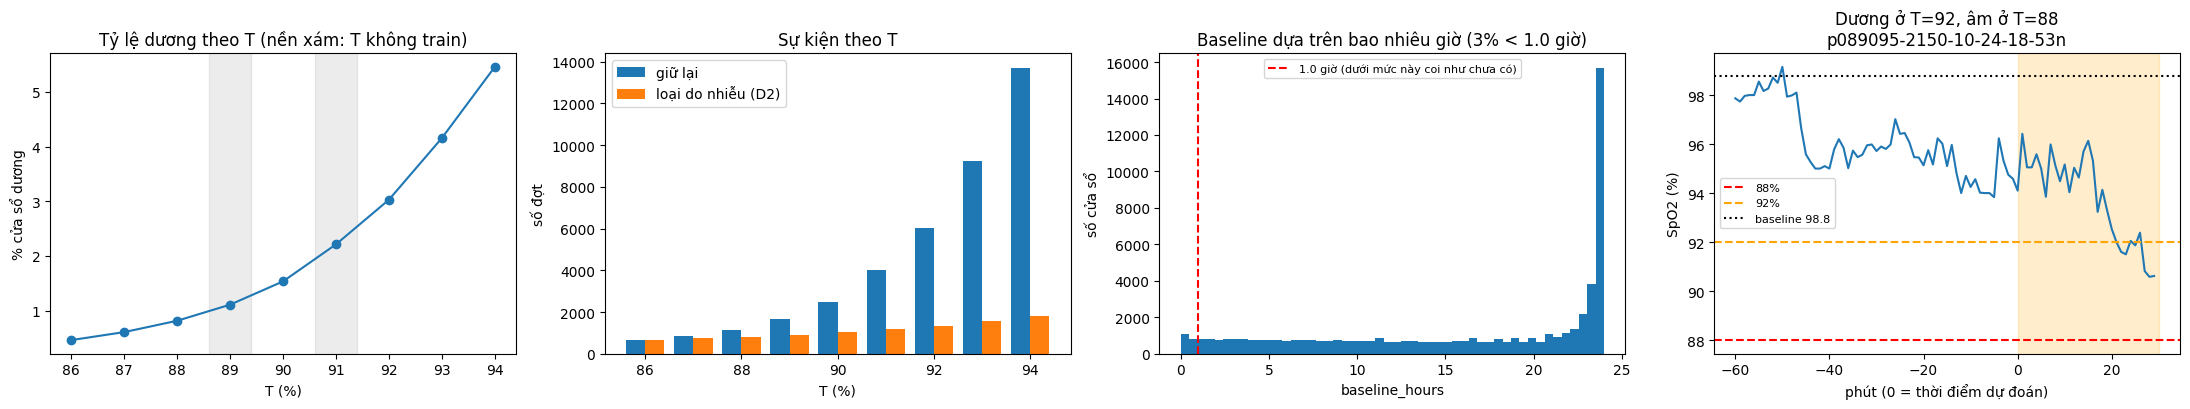

SpO2 5 phút cuối − baseline: trung vị -0.06, p10 -2.72, p90 1.71


In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(22, 4.2))
ax[0].plot(TAB.index, TAB["ty_le_duong"] * 100, "o-")
for t in C.T_HOLDOUT: ax[0].axvspan(t - .4, t + .4, color="gray", alpha=.15)
ax[0].set(xlabel="T (%)", ylabel="% cửa sổ dương", title="Tỷ lệ dương theo T (nền xám: T không train)")
ax[1].bar(TAB.index - .2, TAB["su_kien"], .4, label="giữ lại"); ax[1].bar(TAB.index + .2, TAB["nhieu_bi_loai"], .4, label="loại do nhiễu (D2)")
ax[1].set(xlabel="T (%)", ylabel="số đợt", title="Sự kiện theo T"); ax[1].legend()

rng = np.random.default_rng(0); bh, dl = [], []
for n in rng.choice(SUM.loc[SUM["n_win"] > 0, "name"], min(150, (SUM["n_win"] > 0).sum()), replace=False):
    z = np.load(f"{WIN_DIR}/{n}.npz"); bh.append(z["baseline_hours"])
    dl.append(np.nanmean(z["X"][:, -5:, 0], 1) - z["baseline"])
bh, dl = np.concatenate(bh), np.concatenate(dl)
ax[2].hist(bh, bins=50); ax[2].axvline(C.BASE_MIN_HOURS, c="r", ls="--", label=f"{C.BASE_MIN_HOURS} giờ (dưới mức này coi như chưa có)")
ax[2].set(xlabel="baseline_hours", ylabel="số cửa sổ", title=f"Baseline dựa trên bao nhiêu giờ ({(bh < C.BASE_MIN_HOURS).mean():.0%} < {C.BASE_MIN_HOURS} giờ)"); ax[2].legend(fontsize=8)
j88, j92 = list(T_LIST).index(88), list(T_LIST).index(92)
cand = SUM.loc[SUM[f"pos_92"] > SUM[f"pos_88"], "name"].to_numpy()
if len(cand):
    n = np.random.default_rng().choice(cand); z = np.load(f"{WIN_DIR}/{n}.npz")
    i = np.random.default_rng().choice(np.where(z["Y"][:, j92].astype(bool) & ~z["Y"][:, j88].astype(bool) & z["OK"][:, j92])[0]); s0 = int(z["start"][i])
    full = pd.read_parquet(f"{CLEAN_DIR}/{n}.parquet")["spo2_mean"].to_numpy()[s0: s0 + IN_MIN + HORIZON]
    ax[3].plot(range(-IN_MIN, HORIZON)[:len(full)], full); ax[3].axvspan(0, HORIZON, color="orange", alpha=.2)
    for t, c in ((88, "r"), (92, "orange")): ax[3].axhline(t, ls="--", c=c, label=f"{t}%")
    ax[3].axhline(z["baseline"][i], ls=":", c="k", label=f"baseline {z['baseline'][i]:.1f}")
    ax[3].set(xlabel="phút (0 = thời điểm dự đoán)", ylabel="SpO2 (%)", title=f"Dương ở T=92, âm ở T=88\n{n}"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"SpO2 5 phút cuối − baseline: trung vị {np.nanmedian(dl):.2f}, p10 {np.nanpercentile(dl, 10):.2f}, p90 {np.nanpercentile(dl, 90):.2f}")